In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad

import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import math

import scipy
import random
import statistics
import umap as UM
from scipy.stats import zscore
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans
from sklearn.cluster import SpectralClustering
import seaborn as sns
from IPython.display import clear_output
import muon

from joblib import Parallel, delayed

import sys
sys.path.append('/michorlab/bingxian/multi_modal_unpaired_matching/')
# from utils_MBTA import *
import utils_MBTA
import common_utils

import importlib
importlib.reload(utils_MBTA)
importlib.reload(common_utils)

/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'common_utils' from '/michorlab/bingxian/multi_modal_unpaired_matching/common_utils.py'>

In [2]:
mod1 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/case1_kaggle_RNA.h5ad")
mod2 = sc.read_h5ad("/michorlab/bingxian/multi_modal_unpaired_matching/example_datasets/case1_kaggle_protein.h5ad")


mod1.X = mod1.X.toarray() if hasattr(mod1.X, "toarray") else mod1.X
mod2.X = mod2.X.toarray() if hasattr(mod2.X, "toarray") else mod2.X  # binarize for atac



mod1_tensor = torch.tensor(mod1.X).type(torch.float32)
mod2_tensor = torch.tensor(mod2.X).type(torch.float32)




In [5]:

def run_training(name, tensor):
    print('start')
    torch.set_num_threads(2)
    model = utils_MBTA.train_model(
        tensor,
        Nnodes=200,
        latent_dim=20,
        batchSize=150,
        Ndir=50,
        Niter=20000,
        balance=False
    )
    print(f"done with {name}")
    return name, model

# construct all modality dictionaries for parallel training of the VAE component
all_modalities = {'RNA': mod1_tensor,
                  'protein': mod2_tensor}



results = Parallel(n_jobs=3)(
    delayed(run_training)(name, tensor) for name, tensor in all_modalities.items()
)



start
start
Iter: 0, loss_re: 2842.7703, loss_pcf: 0.0000
reconstruction loss = 2299.7297
Iter: 0, loss_re: 4319.6182, loss_pcf: 0.0000
reconstruction loss = 3784.5024
Iter: 1000, loss_re: 402.4545, loss_pcf: 0.0000
reconstruction loss = 223.3475
Iter: 2000, loss_re: 379.3093, loss_pcf: 0.0000
reconstruction loss = 214.56981
Iter: 1000, loss_re: 1667.0316, loss_pcf: 0.0000
reconstruction loss = 1488.4393
Iter: 3000, loss_re: 347.7599, loss_pcf: 0.0000
reconstruction loss = 168.59593
Iter: 4000, loss_re: 351.5238, loss_pcf: 0.0000
reconstruction loss = 197.61739
Iter: 2000, loss_re: 1576.5422, loss_pcf: 0.0000
reconstruction loss = 1425.9575
Iter: 5000, loss_re: 314.6193, loss_pcf: 0.0000
reconstruction loss = 158.32199
Iter: 6000, loss_re: 304.5543, loss_pcf: 0.0000
reconstruction loss = 160.53586
Iter: 3000, loss_re: 1586.1453, loss_pcf: 0.0000
reconstruction loss = 1423.4712
Iter: 7000, loss_re: 286.6046, loss_pcf: 0.0000
reconstruction loss = 144.8439
Iter: 8000, loss_re: 301.5995, 

In [ ]:
''' 
create a MBTA object from trained models
'''

models = []
for modality_name, model in results:
    models.append(utils_MBTA.MBTA_submodule(model, "MBTA", modality_name))

MBTA = utils_MBTA.general_MBTA()

for i in models:
    MBTA.add_model(i, i.modality_name)


In [ ]:
''' 
parallel training of the flow matching component
'''
def run_FMs(mod1, mod1_name, mod2, mod2_name):
    print(f"start training model that goes from {mod1_name} to {mod2_name}")
    MBTA.paired_training(mod1, mod1_name,
                         mod2, mod2_name,
                         Nitr=100000
                         )
    

all_pairs = [(mod1_tensor, 'RNA', mod2_tensor, 'protein'),
             (mod2_tensor, 'protein', mod1_tensor, 'RNA')]






results = Parallel(n_jobs=3, backend='threading')(
    delayed(run_FMs)(mod1, mod1_name, mod2, mod2_name) for mod1, mod1_name, mod2, mod2_name in all_pairs
)





start training model that goes from RNA to protein
start training model that goes from protein to RNA
done generating source and target
torch.Size([70988, 20])
done generating source and target
torch.Size([70988, 20])
0
0
1000
1000
2000
2000
3000
3000
4000
4000
5000
5000
6000
6000
7000
7000
8000
8000
9000
9000
10000
10000
11000
11000
12000
12000
13000
13000
14000
14000
15000
15000
16000
16000
17000
17000
18000
18000
19000
19000
20000
20000
21000
21000
22000
22000
23000
23000
24000
24000
25000
25000
26000
26000
27000
27000
28000
28000
29000
29000
30000
30000
31000
31000
32000
32000
33000
33000
34000
34000
35000
35000
36000
36000
37000
37000
38000
38000
39000
40000
39000
41000
40000
42000
41000
43000
42000
44000
43000
45000
44000
46000
45000
47000
46000
48000
47000
49000
48000
50000
49000
51000
50000
52000
51000
53000
52000
54000
53000
55000
54000
56000
55000
57000
56000
58000
57000
59000
58000
60000
59000
61000
60000
62000
61000
63000
62000
64000
63000
65000
64000
66000
65000
67000
6600

In [27]:
#generate protein from RNA
a, low_a = MBTA.generate(mod1_tensor, 'RNA',
                  mod2_tensor, 'protein', get_low = True)

# generate RNA from protein
b, low_b = MBTA.generate(mod2_tensor, 'protein',
                  mod1_tensor, 'RNA', get_low = True)

# generate individual low dim representation
low_mod1 = MBTA.RNA.model.latentMean(mod1_tensor).detach().numpy()
low_mod2 = MBTA.protein.model.latentMean(mod2_tensor).detach().numpy()



done generating source and target
torch.Size([70988, 20])
done generating source and target
torch.Size([70988, 20])


In [28]:


pca_low = PCA(n_components = 50, random_state = 1)
reducer2 = UM.UMAP(n_neighbors=10, 
                  metric = 'euclidean', 
                  repulsion_strength=.1, 
                  n_epochs=500, 
                  negative_sample_rate=5, 
                  min_dist = .5,
                  verbose = False,
                  random_state=1,
                  n_components = 2
                 )




In [29]:
l11 = reducer2.fit_transform(low_mod1)
l12 = reducer2.fit_transform(low_mod2)
l2 = reducer2.fit_transform(low_a.detach().numpy())
l3 = reducer2.fit_transform(low_b.detach().numpy())

/michorlab/bingxian/miniforge3/envs/dev/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


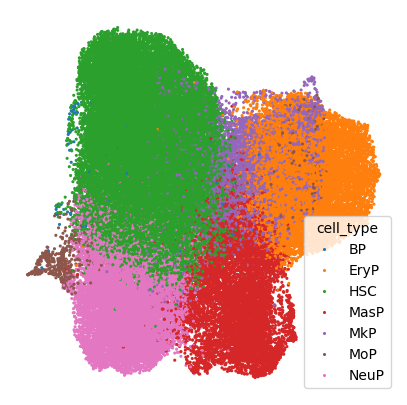

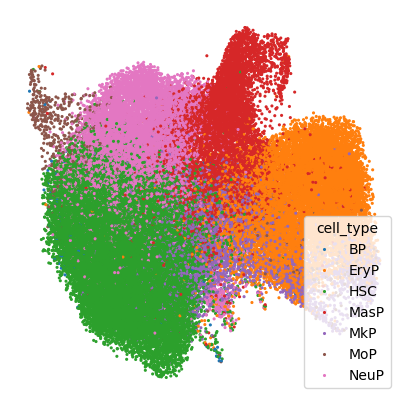

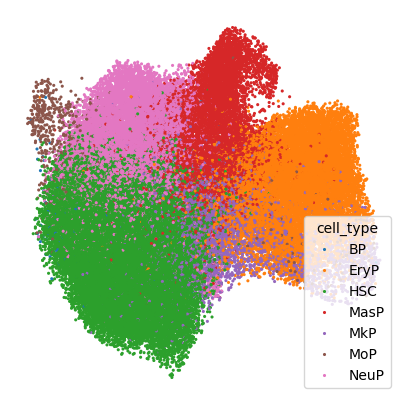

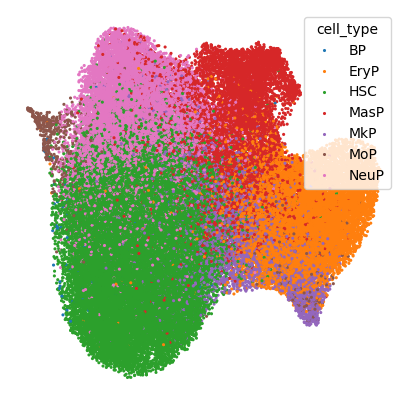

In [ ]:
use_l =  l11
sns.scatterplot(x = use_l[:,0], y =use_l[:,1], hue = mod1.obs.cell_type, linewidth = 0, s = 5, alpha = 1,   
                legend = True)
plt.gcf().set_size_inches(5,5)
plt.axis('off')
plt.show()

use_l =  l12
sns.scatterplot(x = use_l[:,0], y =use_l[:,1], hue = mod1.obs.cell_type, linewidth = 0, s = 5, alpha = 1,   
                legend = True)
plt.gcf().set_size_inches(5,5)
plt.axis('off')
plt.show()

use_l =  l2
sns.scatterplot(x = use_l[:,0], y =use_l[:,1], hue = mod1.obs.cell_type, linewidth = 0, s = 5, alpha = 1,   
                legend = True)
plt.gcf().set_size_inches(5,5)
plt.axis('off')
plt.show()

use_l =  l3
sns.scatterplot(x = use_l[:,0], y =use_l[:,1], hue = mod1.obs.cell_type, linewidth = 0, s = 5, alpha = 1,   
                legend = True)
plt.gcf().set_size_inches(5,5)
plt.axis('off')
plt.show()



In [33]:
df1 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.RNA.predict(mod1_tensor), mod1_tensor.detach().numpy(), b)

df3 = common_utils.common_embedding_3(reducer2, pca_low, MBTA.protein.predict(mod2_tensor), mod2_tensor.detach().numpy(), a)



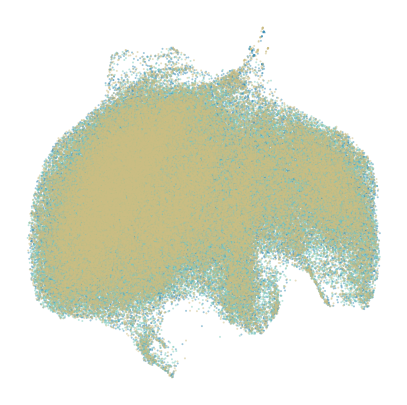

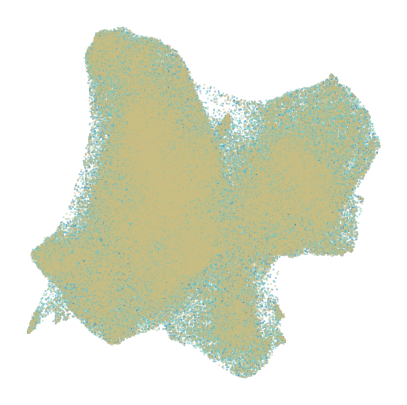

In [ ]:
recon_palette = {'reconstructed':"#3c8fb6", 
                 'translated': '#7dccbe',
                 'real': "#ccbd83" }

recon_palette2 = {'reconstructed':"#4d65a8", 
                 'translated': '#6e8fc2',
                 'real': "#c2b43a" }


# coembedding of real, reconstructed and translated protein
sns.scatterplot(df3, x = 'x', y = 'y', hue = 'hue', linewidth = 0, s = 2, alpha = .5,  palette= recon_palette, legend = False)
plt.gcf().set_size_inches(5,5)
plt.axis('off')
plt.show()

# coembedding of real, reconstructed and translated RNA
sns.scatterplot(df1, x = 'x', y = 'y', hue = 'hue', linewidth = 0, s = 2, alpha = .5,  palette= recon_palette, legend = False)
plt.gcf().set_size_inches(5,5)
plt.axis('off')
plt.show()